In [21]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_curve
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate
warnings.filterwarnings('ignore')

In [22]:
# df = pd.read_csv('datasets/Bikroy1.csv', encoding='latin1')
df = pd.read_csv('datasets/Bikroy2.csv', encoding='latin1')
df.columns

Index(['ï»¿id', 'car_name', 'brand', 'car_model', 'model_year', 'transmission',
       'body_type', 'fuel_type', 'engine_capacity', 'travels', 'price',
       'accident', 'registration'],
      dtype='object')

In [23]:
df['car_age'] = 2024 - df['model_year']
df

,ï»¿id,car_name,brand,car_model,model_year,transmission,body_type,fuel_type,engine_capacity,travels,price,accident,registration,car_age
0,1,MarutiSuzukiWagonRUttara2012,MarutiSuzuki,WagonR,2012,Automatic,Hatchback,Octane,1500,60000.0,2550000.0,N,2025,12
1,2,ToyotaHiace2005,Toyota,Hiace,2005,Automatic,MPV,CNG,2000,32000.0,2000200.0,Y,2024,19
2,3,ToyotaAxio2009,Toyota,Axio,2009,Automatic,Hatchback,CNG,1500,25500.0,2245550.0,N,2023,15
3,4,ToyotaCorsa1999,Toyota,Corsa,1999,Automatic,Hatchback,CNG,1500,90000.0,1120000.0,N,2023,25
4,5,ToyotaCorolla2002,Toyota,Corolla,2002,Automatic,Sedan,CNG,1500,202580.0,2320025.0,N,2023,22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,1139,ToyotaSientaGHybrid2019,Toyota,Sienta,2019,Automatic,MPV,Octane,2000,68436.0,2584016.0,N,2023,5
1139,1140,ToyotaHiaceSuperGL4Point2019,Toyota,Hiace,2019,Automatic,MPV,Octane,2000,56880.0,3637268.0,N,2022,5
1140,1141,ToyotaEsquire2019,Toyota,Esquire,2019,Automatic,MPV,Octane,2000,80738.0,NaN,N,2024,5
1141,1142,ToyotaFielderWxbMicaBlue2019,Toyota,Fielder,2019,Automatic,Wagon,Hybrid,1500,70759.0,2880417.0,N,2024,5


In [24]:
df.isna().sum()

ï»¿id               0
car_name            0
brand               0
car_model           0
model_year          0
transmission        0
body_type           0
fuel_type           0
engine_capacity     0
travels             2
price              14
accident            0
registration        0
car_age             0
dtype: int64

In [25]:
df['travels'].fillna(df['travels'].mean(), inplace=True)
df['price'].fillna(df['price'].mean(), inplace=True)
df.isna().sum()

ï»¿id              0
car_name           0
brand              0
car_model          0
model_year         0
transmission       0
body_type          0
fuel_type          0
engine_capacity    0
travels            0
price              0
accident           0
registration       0
car_age            0
dtype: int64

In [26]:
le_dict = {}
scaler = StandardScaler()
dt_model = DecisionTreeClassifier(random_state=42)
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
feature_columns = None
numerical_cols = ['car_age', 'engine_capacity', 'travels', 'price', 'registration']
categorical_cols = ['brand', 'transmission', 'body_type', 'fuel_type', 'accident']

In [27]:
def preprocess_data(df, is_training=True):
        # Create a copy of the dataframe
        df_processed = df.copy()
        
        # Label encode categorical columns
        for col in categorical_cols:
            if is_training:
                le_dict[col] = LabelEncoder()
                df_processed[col] = le_dict[col].fit_transform(df_processed[col])
            else:
                # Handle unseen categories in user preferences
                try:
                    df_processed[col] = le_dict[col].transform(df_processed[col])
                except ValueError as e:
                    print(f"Warning: Unseen category in {col}. Using most frequent category from training.")
                    # Get the most frequent category from training
                    most_frequent = le_dict[col].inverse_transform([0])[0]
                    df_processed[col] = le_dict[col].transform([most_frequent])
        
        # Scale numerical columns
        if is_training:
            df_processed[numerical_cols] = scaler.fit_transform(df_processed[numerical_cols])
        else:
            df_processed[numerical_cols] = scaler.transform(df_processed[numerical_cols])
        
        return df_processed

In [28]:
preprocess_data(df).head(3)

,ï»¿id,car_name,brand,car_model,model_year,transmission,body_type,fuel_type,engine_capacity,travels,price,accident,registration,car_age
0,1,MarutiSuzukiWagonRUttara2012,4,WagonR,2012,0,4,3,-0.941898,-0.820415,-0.084454,0,1.419821,1.286266
1,2,ToyotaHiace2005,8,Hiace,2005,0,5,0,-0.181477,-1.009885,-0.089052,1,-0.058189,2.812049
2,3,ToyotaAxio2009,8,Axio,2009,0,4,0,-0.941898,-1.053869,-0.087000,0,-1.536200,1.940173


In [29]:
preprocess_data(df, is_training=False).head(3)

,ï»¿id,car_name,brand,car_model,model_year,transmission,body_type,fuel_type,engine_capacity,travels,price,accident,registration,car_age
0,1,MarutiSuzukiWagonRUttara2012,4,WagonR,2012,0,4,3,-0.941898,-0.820415,-0.084454,0,1.419821,1.286266
1,2,ToyotaHiace2005,8,Hiace,2005,0,5,0,-0.181477,-1.009885,-0.089052,1,-0.058189,2.812049
2,3,ToyotaAxio2009,8,Axio,2009,0,4,0,-0.941898,-1.053869,-0.087000,0,-1.536200,1.940173


In [30]:
def visualize_classification_report(y_true, y_pred, model_name: str, figsize=(10, 6)):
    """
    Create a heatmap visualization of the classification report.
    
    Parameters:
    -----------
    y_true : array-like
        True labels
    y_pred : array-like
        Predicted labels
    figsize : tuple, optional (default=(10, 6))
        Figure size for the plot
        
    Returns:
    --------
    fig : matplotlib figure
        The figure object containing the visualization
    """
    # Get classification report as dictionary
    report = classification_report(y_true, y_pred, output_dict=True)
    
    # Convert to DataFrame
    df = pd.DataFrame(report).T
    
    # Drop support column and unwanted rows
    df = df.drop('support', axis=1)
    df = df.drop(['accuracy', 'macro avg', 'weighted avg'])
    
    # Create figure and axis
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create heatmap
    sns.heatmap(df, annot=True, cmap='YlOrRd', fmt='.2f', 
                cbar_kws={'label': 'Score'}, ax=ax)
    
    # Customize appearance
    plt.title(f'Classification Report Visualization for {model_name}', pad=20)
    plt.ylabel('Classes')
    plt.xlabel('Metrics')
    
    # Rotate x-axis labels for better readability
    plt.xticks(rotation=0)
    
    # Adjust layout to prevent label cutoff
    plt.tight_layout()
    
    return fig

In [31]:
def plot_confusion_matrix(y_true, y_pred, model_name: str, figsize=(10, 6)):
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, ax=ax)
    plt.title(f'Confusion Matrix Visualization for {model_name}', pad=20)
    plt.tight_layout()

    return fig


In [32]:
def misclassification_analysis(y_true, y_pred, y_pred_proba):
    """
    Analyze misclassification patterns in the model predictions.
    
    Parameters:
    -----------
    y_true : array-like
        True labels
    y_pred : array-like
        Predicted labels
    y_pred_proba : array-like
        Prediction probabilities
    
    Returns:
    --------
    DataFrame : Detailed misclassification information
    """
    # Create a DataFrame to analyze misclassifications
    misclass_df = pd.DataFrame({
        'true_label': y_true,
        'predicted_label': y_pred,
        'max_confidence': np.max(y_pred_proba, axis=1)
    })
    
    # Identify misclassified instances
    misclassified = misclass_df[misclass_df['true_label'] != misclass_df['predicted_label']]
    
    # Misclassification summary
    misclass_summary = misclassified.groupby([
        'true_label', 'predicted_label'
    ]).agg({
        'max_confidence': ['count', 'mean']
    }).reset_index()
    
    # Rename columns for clarity
    misclass_summary.columns = [
        'true_label', 'predicted_label', 'misclass_count', 'avg_confidence'
    ]
    
    # Sort by misclassification count in descending order
    misclass_summary = misclass_summary.sort_values(
        'misclass_count', 
        ascending=False
    )
    
    print("Misclassification Summary:")
    print(misclass_summary)
    
    return misclass_summary

In [33]:
def train_models(df):
        # Store feature columns
        global feature_columns
        feature_columns = categorical_cols + numerical_cols
        
        # Preprocess the training data
        df_processed = preprocess_data(df, is_training=True)
        
        # Prepare features and target
        X = df_processed[feature_columns]
        y = df_processed['brand']  # Using brand as target for demonstration
        
        # Split the data
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        
        # Train Decision Tree
        dt_model.fit(X_train, y_train)
        dt_pred = dt_model.predict(X_test)
        dt_accuracy = accuracy_score(y_test, dt_pred)
        
        # Train Random Forest
        rf_model.fit(X_train, y_train)
        rf_pred = rf_model.predict(X_test)
        rf_accuracy = accuracy_score(y_test, rf_pred)

        #misclassification analysis DT 
        # missclass_summary_dt = misclassification_analysis(y_test, dt_pred, dt_model.predict_proba(X_test))
        misclassified_dt = pd.DataFrame({
                            "True Label": y_test,
                            "Predicted Label": dt_pred
                            })
        print(misclassified_dt)
        misclassified_dt = misclassified_dt[y_test != dt_pred]

        misclassified_rf = pd.DataFrame({
                            "True Label": y_test,
                            "Predicted Label": rf_pred
                            })
        print(misclassified_rf)
        misclassified_rf = misclassified_dt[y_test != rf_pred]
        
        return {
            'decision_tree': {
                'accuracy': dt_accuracy * 100,
                'report': classification_report(y_test, dt_pred),
                'cf_matrix': confusion_matrix(y_test, dt_pred),
                # 'fig': visualize_classification_report(y_test, dt_pred, model_name="Decision Tree"),
                # 'cf_fig': plot_confusion_matrix(y_test, dt_pred, model_name="Decision Tree")
                'missclass_summary': misclassified_dt
            },
            'random_forest': {
                'accuracy': rf_accuracy * 100,
                'report': classification_report(y_test, rf_pred),
                'cf_matrix': confusion_matrix(y_test, rf_pred),
                # 'fig': visualize_classification_report(y_test, rf_pred, model_name="Random Forest"),
                # 'cf_fig': plot_confusion_matrix(y_test, rf_pred, model_name="Random Forest")
                'missclass_summary': misclassified_rf
                
            },
        }

In [34]:
results = train_models(df)

      True Label  Predicted Label
158            8                8
1081           8                8
291            8                8
538            7                7
367            0                0
...          ...              ...
66             8                8
328            2                2
67             8                8
231            8                8
966            8                8

[229 rows x 2 columns]
      True Label  Predicted Label
158            8                8
1081           8                8
291            8                8
538            7                7
367            0                0
...          ...              ...
66             8                8
328            2                2
67             8                8
231            8                8
966            8                8

[229 rows x 2 columns]


In [35]:
print(results['decision_tree']['missclass_summary'])
print(results['random_forest']['missclass_summary'].sum())

Empty DataFrame
Columns: [True Label, Predicted Label]
Index: []
True Label         0
Predicted Label    0
dtype: int64


In [36]:
print("Model Accuracies:")
print(f"Decision Tree Accuracy: {results['decision_tree']['accuracy']:.4f}")
print("\nDecision Tree Classification Report:")
print(results['decision_tree']['report'])
print(f"\nRandom Forest Accuracy: {results['random_forest']['accuracy']:.4f}")
print("\nRandom Forest Classification Report:")
print(results['random_forest']['report'])

Model Accuracies:
Decision Tree Accuracy: 100.0000

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00         1
           2       1.00      1.00      1.00        29
           5       1.00      1.00      1.00        28
           6       1.00      1.00      1.00         1
           7       1.00      1.00      1.00        36
           8       1.00      1.00      1.00       111

    accuracy                           1.00       229
   macro avg       1.00      1.00      1.00       229
weighted avg       1.00      1.00      1.00       229


Random Forest Accuracy: 99.5633

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00         1
           2       1.00      1.00      1.00        29
           5       0.97   

In [37]:
def recommend_cars(user_preferences, df, top_n=5):
        user_preferences['car_age'] = 2024 - user_preferences['model_year']
        # Verify all required features are present
        missing_features = set(feature_columns) - set(user_preferences.keys())

        if missing_features:
            raise ValueError(f"Missing required features: {missing_features}")
        
        # Create a DataFrame with user preferences
        user_df = pd.DataFrame([user_preferences])
        
        # Preprocess user preferences using the fitted encoders and scaler
        user_df_processed = preprocess_data(user_df, is_training=False)
        
        # Ensure correct feature order
        user_features = user_df_processed[feature_columns]

        # print(user_features.head())
        # Get user's desired brand class
        user_brand_encoded = user_df_processed['brand'].iloc[0]
        print('user_brand_encoded', user_brand_encoded)
        
        # Calculate similarity scores using both models
        user_dt_probs = dt_model.predict_proba(user_features)
        user_rf_probs = rf_model.predict_proba(user_features)

        # print('user_dt_prob', dt_probs.shape)

        # print(dict(zip(le_dict['brand'].classes_, dt_probs)))
        
        # Combine probabilities (ensemble approach)
        user_combined_probs = (user_dt_probs + user_rf_probs) / 2

        print('combined probs: ', user_combined_probs)
        
        # Get recommendations
        df_processed = preprocess_data(df, is_training=False)
        
        # Get model predictions and probabilities for all cars
        dt_probs = dt_model.predict_proba(df_processed[feature_columns])
        rf_probs = rf_model.predict_proba(df_processed[feature_columns])
        combined_probs = (dt_probs + rf_probs) / 2
        # print('similarity_scores_dt = ', dt_probs @ user_dt_probs.T)

        similarity_scores_dt =  (dt_probs @ user_dt_probs.T) * 100
        similarity_scores_rf =  (rf_probs @ user_rf_probs.T) * 100
        similarity_scores_combined =  (combined_probs @ user_combined_probs.T) * 100

        # Create a DataFrame to store results
        results = pd.DataFrame({
            'dataset_index': df.index,
            'similarity_score_dt': similarity_scores_dt.flatten(),
            'similarity_score_rf': similarity_scores_rf.flatten(),
            'similarity_score_combined': similarity_scores_combined.flatten(),
        })
        print(results.sort_values(by='similarity_score_rf', ascending=False))
        results = results.sort_values(by='similarity_score_combined', ascending=False).head(top_n)
        print('dt_probs: ', dt_probs.shape)
        recommendations = df.iloc[results.index]
        
        return recommendations

In [ ]:
example_preferences = {
    'model_year': 2020,
    'transmission': 'Automatic',
    'body_type': 'SUV',
    'fuel_type': 'CNG',
    'engine_capacity': 1500,
    'travels': 30000,
    'price': 45000,
    'accident': 'No',
    'registration': 2024,
    'brand': 'Toyota'  
}

In [39]:
# Get recommendations
recommendations = recommend_cars(example_preferences, df)
print("\nTop 5 Recommended Cars:")
print(recommendations[['car_name', 'brand', 'car_age', 'price', 'travels']].to_string())

user_brand_encoded 8
combined probs:  [[0.    0.    0.    0.    0.    0.    0.    0.005 0.995]]
      dataset_index  similarity_score_dt  similarity_score_rf  \
1142           1142                100.0                 99.0   
1141           1141                100.0                 99.0   
1                 1                100.0                 99.0   
2                 2                100.0                 99.0   
3                 3                100.0                 99.0   
...             ...                  ...                  ...   
620             620                  0.0                  0.0   
577             577                  0.0                  0.0   
353             353                  0.0                  0.0   
267             267                  0.0                  0.0   
311             311                  0.0                  0.0   

      similarity_score_combined  
1142                       99.5  
1141                       99.5  
1                    

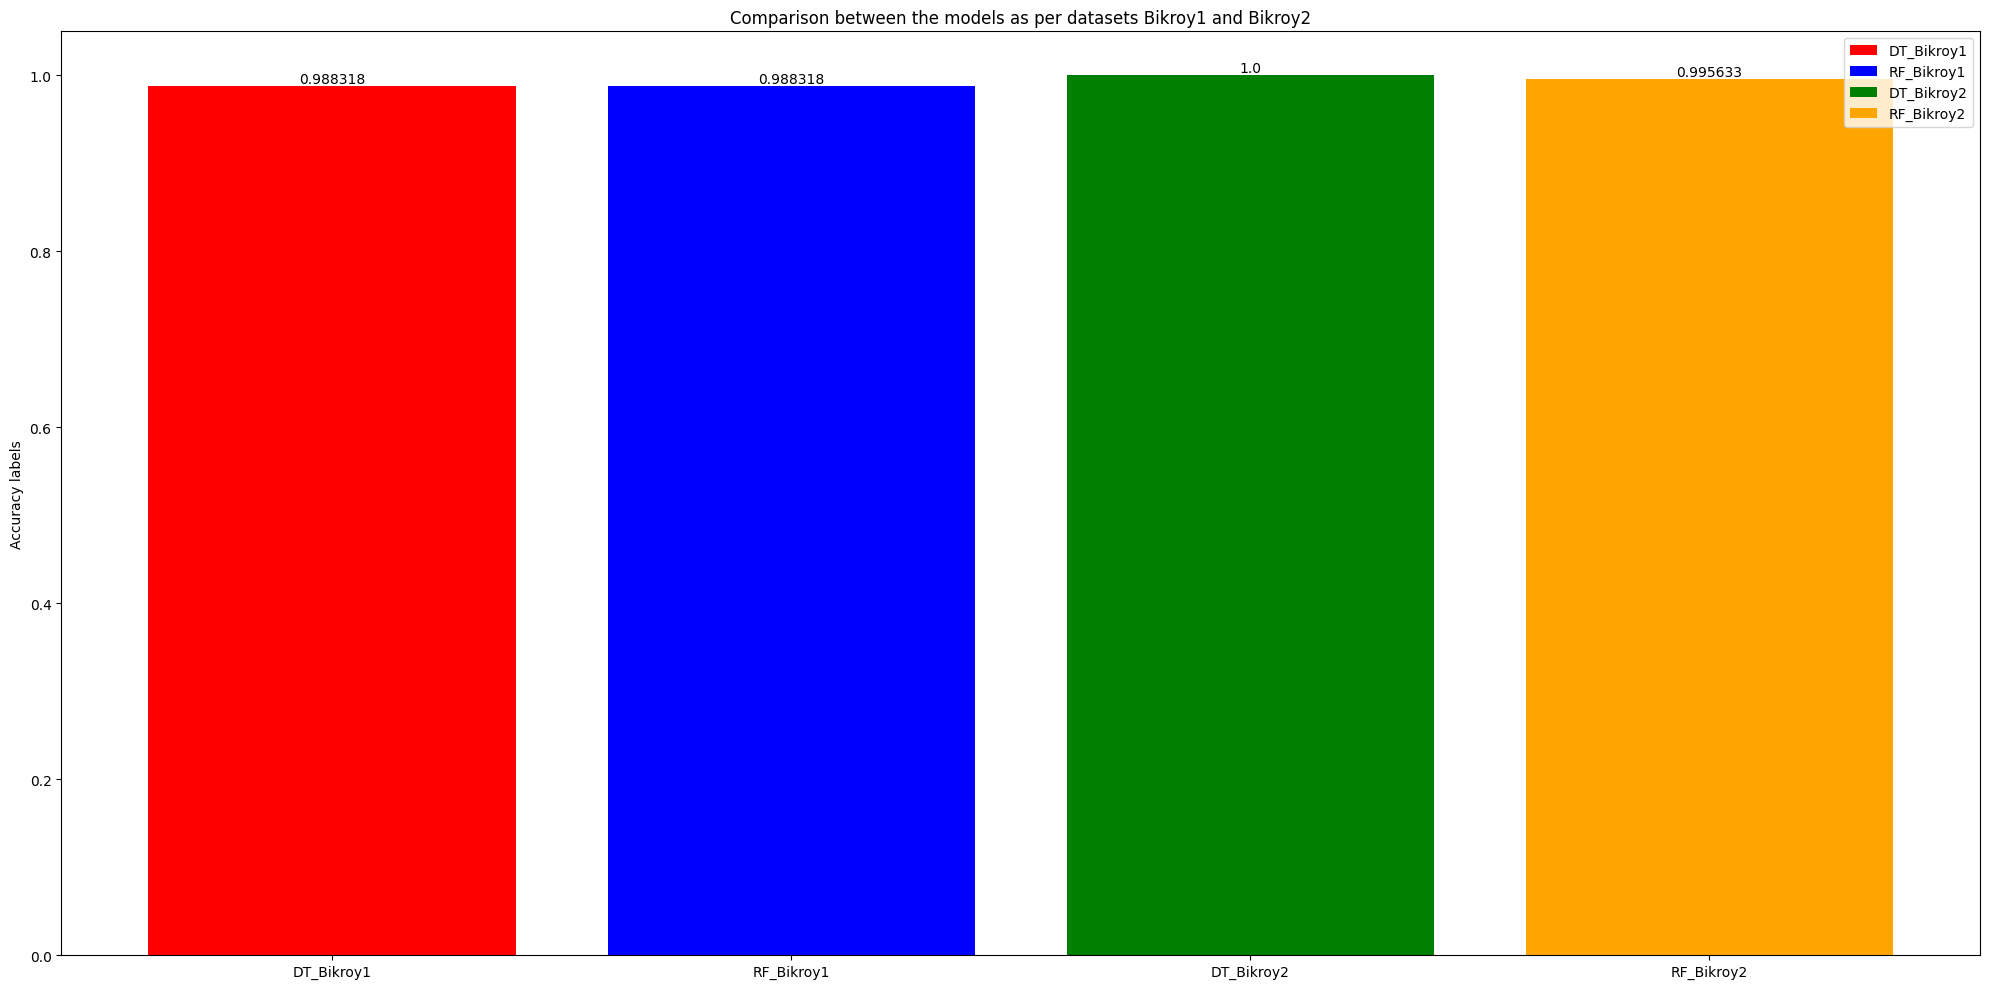

In [40]:
x_labels = ["DT_Bikroy1", "RF_Bikroy1", "DT_Bikroy2", "RF_Bikroy2"]
x = np.arange(len(x_labels))
width = 0.2
accuracy = {
    "DT_Bikroy1": 0.988318,
    "RF_Bikroy1": 0.988318,
    "DT_Bikroy2": 1,
    "RF_Bikroy2": 0.995633
}

values = [0.988318,0.988318,1,0.995633]
colors = ['red', 'blue', 'green', 'orange']
# Create the bar plot
plt.figure(figsize=(20, 10))
bars = plt.bar(x_labels, values, color=colors)

# Add annotations on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height}', ha='center', va='bottom')

# Add labels and title
# plt.xlabel("Items")
plt.ylabel("Accuracy labels")
plt.title("Comparison between the models as per datasets Bikroy1 and Bikroy2")
for bar, item in zip(bars, x_labels):
    bar.set_label(item)
plt.legend(x_labels)

# Show the plot
plt.tight_layout()
plt.show()